In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

def ic95(x):
    x = np.asarray(x, float); n = len(x)
    h = stats.t.ppf(.975, n-1)*x.std(ddof=1)/np.sqrt(n)
    return x.mean(), h

In [2]:
import numpy as np, heapq
from collections import deque
from math import factorial

MU = 2.0

def simular_des(lam, c, K=60, T=720.0, warm=120.0, mu=MU, rng=None, vaciar=True, traza=False):
    """M/M/c/K FIFO. Mide sobre [warm, T].
    - W, Wq: de las solicitudes ACEPTADAS que llegan en [warm, T]; si vaciar=True se siguen
      hasta su salida (sin nuevas llegadas tras T) para no truncar sus tiempos.
    - L, Lq, ocupados: promedios temporales en [warm, T].
    - r: rechazadas / llegadas en [warm, T].
    Devuelve dict con métricas y contadores para balance de entidades."""
    rng = rng or np.random.default_rng()
    t = 0.0
    ev = []
    heapq.heappush(ev, (rng.exponential(1/lam), 0, -1))   # (t, tipo 0=llegada 1=salida, id)
    n = 0; ocup = 0; cola = deque()
    t_lleg = {}; t_ini = {}
    sig = 0
    # acumuladores temporales en [warm, T]
    aL = aLq = aB = 0.0; t_prev = 0.0
    W_list = []; Wq_list = []
    cnt = dict(lleg_tot=0, lleg_med=0, rech_tot=0, rech_med=0, atend_tot=0, atend_med=0,
               N_warm=None, N_T=None)
    medir = set()
    tr_t, tr_n = [0.0], [0]
    while ev:
        tn, tipo, cid = heapq.heappop(ev)
        if tipo == 0 and tn > T:          # no más llegadas tras T
            continue
        # integrar áreas entre t_prev y min(tn, T) dentro de [warm, T]
        a0, a1 = max(t_prev, warm), min(tn, T)
        if a1 > a0:
            aL += n*(a1-a0); aLq += (n-ocup)*(a1-a0); aB += ocup*(a1-a0)
        if cnt['N_warm'] is None and tn >= warm:
            cnt['N_warm'] = n
        if cnt['N_T'] is None and tn >= T:
            cnt['N_T'] = n
            if not vaciar:
                break
        t_prev = tn; t = tn
        if traza and tn <= T: tr_t.append(tn)
        if tipo == 0:
            heapq.heappush(ev, (t + rng.exponential(1/lam), 0, -1))
            cnt['lleg_tot'] += 1
            en_med = t >= warm
            cnt['lleg_med'] += en_med
            if n >= K:
                cnt['rech_tot'] += 1; cnt['rech_med'] += en_med
                if traza and len(tr_n) < len(tr_t): tr_n.append(n)
                continue
            cid = sig; sig += 1
            n += 1; t_lleg[cid] = t
            if en_med: medir.add(cid)
            if ocup < c:
                ocup += 1; t_ini[cid] = t
                heapq.heappush(ev, (t + rng.exponential(1/mu), 1, cid))
            else:
                cola.append(cid)
        else:
            n -= 1
            if t <= T:
                cnt['atend_tot'] += 1; cnt['atend_med'] += (t >= warm)
            if cid in medir:
                W_list.append(t - t_lleg[cid]); Wq_list.append(t_ini[cid] - t_lleg[cid])
            del t_lleg[cid]; t_ini.pop(cid, None)
            if cola:
                nid = cola.popleft(); t_ini[nid] = t
                heapq.heappush(ev, (t + rng.exponential(1/mu), 1, nid))
            else:
                ocup -= 1
        if traza and t <= T and len(tr_n) < len(tr_t): tr_n.append(n)
    if cnt['N_T'] is None: cnt['N_T'] = n
    if cnt['N_warm'] is None: cnt['N_warm'] = n
    Tm = T - warm
    acept_med = cnt['lleg_med'] - cnt['rech_med']
    return dict(W=np.mean(W_list) if W_list else 1/mu,
                Wq=np.mean(Wq_list) if Wq_list else 0.0,
                L=aL/Tm, Lq=aLq/Tm, B=aB/Tm, util=aB/Tm/c,
                lam_eff=acept_med/Tm,
                r=cnt['rech_med']/cnt['lleg_med'] if cnt['lleg_med'] else 0.0,
                traza=(np.array(tr_t), np.array(tr_n)) if traza else None, **cnt)

# ---------------- teoría ----------------
def erlang_c(c, A):
    s = sum(A**k/factorial(k) for k in range(c))
    tc = A**c/factorial(c)*c/(c-A)
    return tc/(s+tc)

def mmc(lam, c, mu=MU):
    A = lam/mu; C = erlang_c(c, A)
    Wq = C/(c*mu-lam)
    return dict(W=Wq+1/mu, Wq=Wq, util=A/c, Lq=lam*Wq, L=lam*(Wq+1/mu), C=C)

def mmck(lam, c, K, mu=MU):
    A = lam/mu
    p = np.array([A**n/factorial(n) if n <= c else A**c/factorial(c)*(A/c)**(n-c)
                  for n in range(K+1)], float)
    p /= p.sum()
    n = np.arange(K+1)
    L = (n*p).sum(); Lq = (np.maximum(n-c, 0)*p).sum()
    lam_eff = lam*(1-p[K])
    return dict(PK=p[K], L=L, Lq=Lq, W=L/lam_eff, Wq=Lq/lam_eff,
                util=lam_eff/(c*mu), lam_eff=lam_eff, p=p)


## Capa SD y versiones del híbrido
- **`hibrido_eventos`:** RK4 propio con paso $h$. El paso nunca salta un evento de tiempo (intercambio o llegada de servidores). El cruce $\rho_{pred}\uparrow\theta$ se localiza **por bisección** dentro del paso.
- **`hibrido_eventos_ivp`:** la misma lógica con `solve_ivp(events=...)`, para contrastar.
- **`hibrido_ingenuo`:** revisa el umbral y la llegada solo al final de cada paso $\Delta t$. Su SD se integra igual de bien (sub-pasos RK4 de tamaño $h$), así que la única diferencia es la detección.
- **`intercambio`:** usa semilla $(\text{seed},k)$, es decir **números aleatorios comunes**. Así todas las versiones ven el mismo ruido en el intercambio $k$.
- **`latencia_real`:** evalúa la $W$ exacta de M/M/$c$/$K$ con $U(t)$ y $c(t)$ instantáneos. Es la latencia que vive el usuario, no la $W$ congelada del último intercambio.

In [3]:
import numpy as np
from scipy.integrate import solve_ivp

# ---------------- parámetros (grupo 3) ----------------
P = dict(p=0.002, q=0.30, M=20000.0, U0=100.0, d0=0.003, kW=1.0, kR=0.5, Wok=0.75,
         a=0.0005, mu=MU, K=60, theta=0.7, lote=2, D=5.0, c0=4, T=100.0, H=1.0,
         h=0.05, modo='des')
# h = paso RK4 escogido en el Task 2.2; modo='des' (simulación) o 'teoria' (M/M/c/K exacta, sin ruido)

def f_U(U, P, W, r):
    delta = P['d0'] + P['kW']*max(0.0, W - P['Wok']) + P['kR']*r
    return (P['p'] + P['q']*U/P['M'])*(P['M'] - U) - delta*U

def rho_pred(U, c, P):
    return P['a']*U/(c*P['mu'])

def paso_rk4(U, h, P, W, r):
    k1 = f_U(U, P, W, r); k2 = f_U(U + h/2*k1, P, W, r)
    k3 = f_U(U + h/2*k2, P, W, r); k4 = f_U(U + h*k3, P, W, r)
    return U + h/6*(k1 + 2*k2 + 2*k3 + k4)

def intercambio(P, U, c, k, seed):
    """Ventana DES del intercambio k. Semilla (seed, k): números aleatorios comunes entre versiones."""
    lam = P['a']*U
    if P['modo'] == 'teoria':
        m = mmck(lam, c, P['K'], P['mu']); return m['W'], m['PK']
    out = simular_des(lam, c, K=P['K'], mu=P['mu'], rng=np.random.default_rng([seed, k]))
    return out['W'], out['r']

def _prep(P, feedback, kw):
    P = dict(P, **kw)
    if not feedback: P['kW'] = P['kR'] = 0.0
    return P

def _salida(ts, Us, U, c, pedidos, llegadas, log, P):
    log = np.array(log)
    return dict(t=np.array(ts), U=np.array(Us), U100=U, c=c, pedidos=pedidos,
                llegadas=llegadas, Wmax=log[:, 3].max(), rmax=log[:, 4].max(), log=log, P=P)

# ------------- (1) evento de estado con RK4 propio + bisección -------------
def hibrido_eventos(P=P, seed=0, feedback=True, tol=1e-10, **kw):
    P = _prep(P, feedback, kw)
    h, T, H = P['h'], P['T'], P['H']
    U_cr = lambda c: P['theta']*c*P['mu']/P['a']           # U donde rho_pred = theta
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = H
    ts, Us = [0.0], [U]
    while t < T - 1e-12:
        # el paso nunca salta un evento de tiempo (intercambio o llegada)
        t_obj = min(t + h, t_sig_H, T, t_arr if t_arr is not None else np.inf)
        hh = t_obj - t
        U_new = paso_rk4(U, hh, P, W, r)
        g0, g1 = U - U_cr(c), U_new - U_cr(c)
        if t_arr is None and g0 < 0 <= g1:                  # cruce hacia arriba dentro del paso
            lo, hi = 0.0, hh                                # bisección sobre el sub-paso RK4
            while hi - lo > tol:
                mid = (lo + hi)/2
                if paso_rk4(U, mid, P, W, r) - U_cr(c) >= 0: hi = mid
                else: lo = mid
            t, U = t + hi, paso_rk4(U, hi, P, W, r)
            ts.append(t); Us.append(U)
            pedidos.append(t); t_arr = t + P['D']
            continue
        t, U = t_obj, U_new
        ts.append(t); Us.append(U)
        if t_arr is not None and abs(t - t_arr) < 1e-9:   # evento de tiempo: llegan servidores
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:              # reorden inmediato
                pedidos.append(t); t_arr = t + P['D']
        if abs(t - t_sig_H) < 1e-9 and t < T - 1e-12:      # intercambio SD -> DES -> SD
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += H
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- (1b) la misma lógica con solve_ivp(events=...) para contraste -------------
def hibrido_eventos_ivp(P=P, seed=0, feedback=True, **kw):
    P = _prep(P, feedback, kw)
    T, H = P['T'], P['H']
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = H
    ts, Us = [0.0], [U]
    while t < T - 1e-12:
        t_fin = min(t_sig_H, T, t_arr if t_arr is not None else np.inf)
        cc = c
        ev = lambda tt, y: rho_pred(y[0], cc, P) - P['theta']
        ev.terminal, ev.direction = True, 1
        sol = solve_ivp(lambda tt, y: [f_U(y[0], P, W, r)], (t, t_fin), [U], method='DOP853',
                        rtol=1e-11, atol=1e-8, events=[ev] if t_arr is None else None)
        if sol.status == 1:
            t, U = sol.t_events[0][0], sol.y_events[0][0][0]
            ts.append(t); Us.append(U); pedidos.append(t); t_arr = t + P['D']; continue
        ts += list(sol.t[1:]); Us += list(sol.y[0, 1:]); t, U = sol.t[-1], sol.y[0, -1]
        if t_arr is not None and abs(t - t_arr) < 1e-9:
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:
                pedidos.append(t); t_arr = t + P['D']
        if abs(t - t_sig_H) < 1e-9 and t < T - 1e-12:
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += H
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- (2) versión ingenua: revisa el umbral solo al final de cada paso Δt -------------
def hibrido_ingenuo(P=P, dt=1.0, seed=0, feedback=True, **kw):
    P = _prep(P, feedback, kw)
    sub = max(1, int(round(dt/P['h'])))                # el SD se integra igual de bien (RK4, h)
    U, c, t = P['U0'], P['c0'], 0.0
    t_arr = None; pedidos, llegadas = [], []
    k = 0; W, r = intercambio(P, U, c, k, seed)
    log = [(0.0, U, c, W, r)]; t_sig_H = P['H']
    ts, Us = [0.0], [U]
    for i in range(int(round(P['T']/dt))):
        for _ in range(sub):
            U = paso_rk4(U, dt/sub, P, W, r)
        t = (i + 1)*dt
        ts.append(t); Us.append(U)
        if t_arr is not None and t >= t_arr - 1e-9:      # la llegada también se ve al final del paso
            c += P['lote']; llegadas.append(t); t_arr = None
            if rho_pred(U, c, P) > P['theta']:
                pedidos.append(t); t_arr = t + P['D']
        if t_arr is None and rho_pred(U, c, P) > P['theta']:   # chequeo ingenuo del umbral
            pedidos.append(t); t_arr = t + P['D']
        if t >= t_sig_H - 1e-9 and t < P['T'] - 1e-9:
            k += 1; W, r = intercambio(P, U, c, k, seed); t_sig_H += P['H']
            log.append((t, U, c, W, r))
    return _salida(ts, Us, U, c, pedidos, llegadas, log, P)

# ------------- métrica continua: latencia que realmente vive el usuario -------------
def latencia_real(R, paso=0.01):
    """W(t) = M/M/c/K exacta con U(t) y c(t) instantáneos (no la W congelada del intercambio)."""
    P = R['P']; tg = np.arange(0, P['T'] + 1e-9, paso)
    Ug = np.interp(tg, R['t'], R['U'])
    cg = P['c0'] + P['lote']*np.searchsorted(np.array(R['llegadas']), tg, side='right')
    Wg = np.array([mmck(P['a']*u, int(c), P['K'], P['mu'])['W'] for u, c in zip(Ug, cg)])
    rho = P['a']*Ug/(cg*P['mu'])
    return dict(t=tg, W=Wg, rho=rho, Wmax=Wg.max(), rho_max=rho.max(),
                exceso=np.trapezoid(np.maximum(0, Wg - P['Wok']), tg),      # s·día sobre W_ok
                dias_sat=paso*np.sum(rho >= 1))


---
# Task 2.1 — Capa DES contra la teoría
## 2.1a  $\lambda=6$, $c=4$, $K\to\infty$, 30 réplicas
- $A=\lambda/\mu=3$ y $\rho=0.75$.
- Teoría M/M/$c$: $W_q=C(c,A)/(c\mu-\lambda)$, $W=W_q+1/\mu$ y utilización $\rho=A/c$.

In [4]:
R30 = 30
rep_a = [simular_des(6, 4, K=10**9, rng=np.random.default_rng([21, i])) for i in range(R30)]
th = mmc(6, 4)
filas = []
for k, nom in [('W','Latencia W (s)'), ('Wq','Espera en cola Wq (s)'), ('util','Utilización ρ'),
               ('L','L (solicitudes)'), ('Lq','Lq (solicitudes)')]:
    m, h = ic95([x[k] for x in rep_a])
    filas.append(dict(métrica=nom, simulado=m, IC95_inf=m-h, IC95_sup=m+h, teoría=th[k],
                      error_rel_pct=100*(m-th[k])/th[k], teoría_en_IC=(m-h <= th[k] <= m+h)))
t21a = pd.DataFrame(filas).set_index('métrica'); t21a

,simulado,IC95_inf,IC95_sup,teoría,error_rel_pct,teoría_en_IC
métrica,,,,,,
Latencia W (s),0.7515,0.7285,0.7744,0.7547,-0.4310,True
Espera en cola Wq (s),0.2511,0.2293,0.2729,0.2547,-1.4230,True
Utilización ρ,0.7514,0.7441,0.7588,0.7500,0.1925,True
L (solicitudes),4.5164,4.3621,4.6708,4.5283,-0.2625,True
Lq (solicitudes),1.5106,1.3747,1.6466,1.5283,-1.1556,True


**Resultado 2.1a.**
- Las cinco métricas contienen el valor teórico dentro de su IC 95 %.
- Los errores relativos son menores a 1.5 %: $W$ = 0.7515 contra 0.7547 s, $W_q$ = 0.2511 contra 0.2547 s y $\rho$ = 0.7514 contra 0.75.
- La capa DES reproduce M/M/$c$.

## 2.1b  $\lambda=10$, $c=4$, $K=60$ (sobrecarga, $\rho=1.25$)

In [5]:
rep_b = [simular_des(10, 4, K=60, rng=np.random.default_rng([22, i])) for i in range(R30)]
m, h = ic95([x['r'] for x in rep_b])
ex = mmck(10, 4, 60)
print(f"r simulada          = {m:.4f}  ± {h:.4f}  (IC 95 %)")
print(f"aproximación 1-cμ/λ = {1-4*2/10:.4f}")
print(f"exacta P_K M/M/c/K  = {ex['PK']:.7f}")
print(f"W simulada          = {np.mean([x['W'] for x in rep_b]):.3f} s   (exacta {ex['W']:.3f} s,  ≈ K/(cμ) = {60/8:.3f} s)")

# ¿cuándo deja de servir la aproximación?
lams = [6, 7, 7.5, 8, 8.5, 9, 10, 12, 16]
tab = []
for lam in lams:
    e = mmck(lam, 4, 60); sim = np.mean([simular_des(lam, 4, K=60, rng=np.random.default_rng([23, j]))['r'] for j in range(10)])
    tab.append(dict(λ=lam, ρ=lam/8, aprox=max(0, 1-8/lam), exacta_PK=e['PK'], simulada_10rep=sim,
                    P_servidor_libre=e['p'][:4].sum()))
pd.DataFrame(tab).set_index('λ')

r simulada          = 0.1981  ± 0.0060  (IC 95 %)
aproximación 1-cμ/λ = 0.2000
exacta P_K M/M/c/K  = 0.2000004
W simulada          = 7.005 s   (exacta 7.000 s,  ≈ K/(cμ) = 7.500 s)


,ρ,aprox,exacta_PK,simulada_10rep,P_servidor_libre
λ,,,,,
6.0000,0.7500,0.0000,0.0000,0.0000,0.4906
7.0000,0.8750,0.0000,0.0001,0.0000,0.2622
7.5000,0.9375,0.0000,0.0015,0.0016,0.1380
8.0000,1.0000,0.0000,0.0169,0.0188,0.0375
8.5000,1.0625,0.0588,0.0605,0.0623,0.0040
9.0000,1.1250,0.1111,0.1112,0.1204,0.0003
10.0000,1.2500,0.2000,0.2000,0.2033,0.0000
12.0000,1.5000,0.3333,0.3333,0.3380,0.0000
16.0000,2.0000,0.5000,0.5000,0.5023,0.0000


**Resultado 2.1b.** Los tres valores son prácticamente iguales: $r$ simulada = 0.198 ± 0.006, la aproximación da 0.2000 y la exacta $P_K$ = 0.2000004.

**Por qué $1-c\mu/\lambda$ es una aproximación.** Por conservación de flujo, lo que se acepta es lo que se atiende:
$$\lambda(1-P_K)=\mu\,\mathbb E[B]\le c\mu\;\Rightarrow\;P_K = 1-\frac{c\mu}{\lambda}\cdot\frac{\mathbb E[B]}{c}\;\ge\;1-\frac{c\mu}{\lambda}.$$
- **Supuesto oculto:** la igualdad solo vale si los $c$ servidores están **siempre** ocupados, es decir $P(N<c)=0$. Es un argumento de fluido que ignora la aleatoriedad y el tamaño finito de $K$.
- **Por qué aquí casi no se nota:** con $\rho=1.25$ y $K=60$ se tiene $P(N<4)\approx4\times10^{-6}$, y por eso el error es de $10^{-7}$.
- **Dónde falla:** cerca de $\rho=1$ o con $K$ pequeño. Con $\lambda=8$ la aproximación da 0 y la exacta 0.017; con $\lambda=7.5$ da 0 contra 0.0015.
- **Además es un resultado estacionario:** una ventana que arranca vacía no rechaza nada durante los primeros $\approx K/(\lambda-c\mu)=30$ s. Ese tramo lo absorbe el calentamiento.
- **Latencia:** $W$ = 7.005 s contra 7.000 s exacta. La cota de fluido $K/(c\mu)=7.5$ s también la sobrestima.

## 2.1c  Ley de Little sobre la simulación
Con $\lambda_{ef}$ = aceptadas en la ventana medida / 600 s, se comparan tres pares:
- $L$ contra $\lambda_{ef}W$ (latencia);
- $L_q$ contra $\lambda_{ef}W_q$ (espera en cola);
- $B=c\,\hat\rho$ contra $\lambda_{ef}\,\overline{S}$ (utilización), con $\overline{S}=W-W_q$ el servicio medio medido.

In [6]:
def little(reps, nombre):
    out = []
    for lhs, rhs, nom in [('L', lambda x: x['lam_eff']*x['W'], 'L = λ·W'),
                          ('Lq', lambda x: x['lam_eff']*x['Wq'], 'Lq = λ·Wq'),
                          ('B', lambda x: x['lam_eff']*(x['W']-x['Wq']), 'c·ρ = λ·E[S]')]:
        a = np.array([x[lhs] for x in reps]); b = np.array([rhs(x) for x in reps])
        err = (b - a)/a
        out.append(dict(escenario=nombre, relación=nom, lado_tiempo=a.mean(), lado_Little=b.mean(),
                        err_rel_medio_pct=100*err.mean(), err_rel_max_abs_pct=100*np.abs(err).max()))
    return out
t21c = pd.DataFrame(little(rep_a, 'λ=6, K=∞') + little(rep_b, 'λ=10, K=60')).set_index(['escenario','relación'])
t21c

lado_tiempo  lado_Little  err_rel_medio_pct  \
escenario  relación                                                    
λ=6, K=∞   L = λ·W            4.5164       4.5181             0.0331   
           Lq = λ·Wq          1.5106       1.5116             0.0500   
           c·ρ = λ·E[S]       3.0058       3.0064             0.0212   
λ=10, K=60 L = λ·W           55.9013      55.8828            -0.0334   
           Lq = λ·Wq         51.9013      51.8845            -0.0327   
           c·ρ = λ·E[S]       4.0000       3.9984            -0.0411   

                         err_rel_max_abs_pct  
escenario  relación                           
λ=6, K=∞   L = λ·W                    0.8325  
           Lq = λ·Wq                  1.5657  
           c·ρ = λ·E[S]               0.4406  
λ=10, K=60 L = λ·W                    0.3454  
           Lq = λ·Wq                  0.3319  
           c·ρ = λ·E[S]               0.5234

**Resultado 2.1c.**
- Los tres pares de Little cierran con error relativo medio de 0.02–0.05 % en ambos escenarios. El error máximo por réplica es de 1.6 %.
- El error residual es un **efecto de borde**:
  - el lado temporal ($L$, $L_q$, $B$) se corta en 720 s, mientras $W$ incluye el vaciado de las solicitudes que siguen dentro;
  - en 120 s ya hay solicitudes dentro que no entran en $\lambda_{ef}$.
- El error baja con ventanas más largas.

---
# Task 2.2 — Capa SD con abandono constante $\delta=\delta_0$
## 2.2a  RK4 propio contra `solve_ivp`
- Con $W<W_{ok}$ y $r=0$ el abandono es $\delta=\delta_0$.
- **Referencia "verdad":** `DOP853` con `rtol=1e-13`.
- **Comparación pedida:** `solve_ivp` (`RK45`) con `rtol=atol=1e-10`.
- **Integrador propio:** RK4 con $h=0.05$ días.

max |RK4(h=0.05) - solve_ivp 1e-10| = 1.60e-05 usuarios
max |RK4(h=0.05) - referencia DOP853| = 4.95e-06 usuarios
max |solve_ivp 1e-10 - referencia|    = 1.12e-05 usuarios
U(100): RK4 = 19801.337703, solve_ivp = 19801.337703


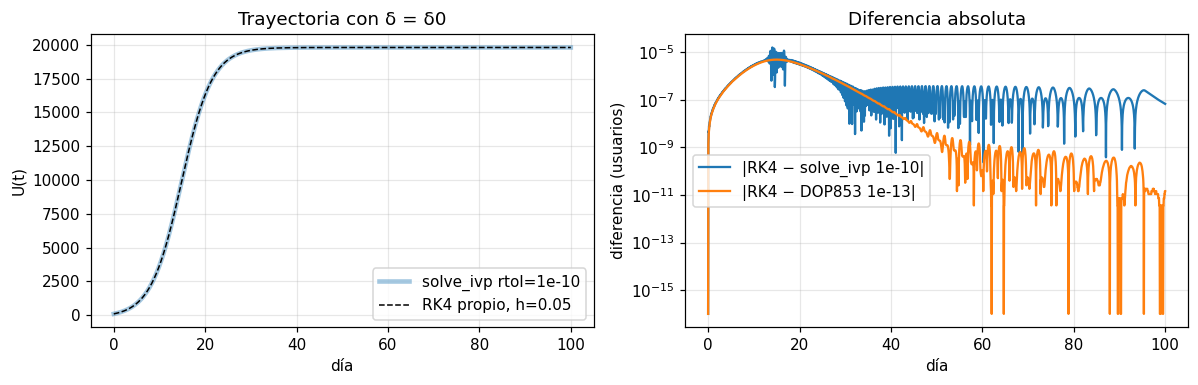

In [7]:
fSD = lambda t, y: [f_U(y[0], P, 0.0, 0.0)]
tg = np.arange(0, 100.0001, P['h'])
ref = solve_ivp(fSD, (0, 100), [P['U0']], method='DOP853', rtol=1e-13, atol=1e-9, t_eval=tg, dense_output=True)
ivp10 = solve_ivp(fSD, (0, 100), [P['U0']], method='RK45', rtol=1e-10, atol=1e-10, t_eval=tg)

def integrar(h, metodo, T=100.0):
    n = int(round(T/h)); U = np.empty(n+1); U[0] = P['U0']
    for i in range(n):
        U[i+1] = U[i] + h*f_U(U[i], P, 0., 0.) if metodo == 'euler' else paso_rk4(U[i], h, P, 0., 0.)
    return np.linspace(0, T, n+1), U

t_rk, U_rk = integrar(P['h'], 'rk4')
print(f"max |RK4(h=0.05) - solve_ivp 1e-10| = {abs(U_rk - ivp10.y[0]).max():.2e} usuarios")
print(f"max |RK4(h=0.05) - referencia DOP853| = {abs(U_rk - ref.y[0]).max():.2e} usuarios")
print(f"max |solve_ivp 1e-10 - referencia|    = {abs(ivp10.y[0] - ref.y[0]).max():.2e} usuarios")
print(f"U(100): RK4 = {U_rk[-1]:.6f}, solve_ivp = {ivp10.y[0][-1]:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ivp10.t, ivp10.y[0], lw=3, alpha=.4, label='solve_ivp rtol=1e-10')
ax[0].plot(t_rk, U_rk, 'k--', lw=1, label='RK4 propio, h=0.05')
ax[0].set(xlabel='día', ylabel='U(t)', title='Trayectoria con δ = δ0'); ax[0].legend()
ax[1].semilogy(t_rk, np.abs(U_rk - ivp10.y[0]) + 1e-16, label='|RK4 − solve_ivp 1e-10|')
ax[1].semilogy(t_rk, np.abs(U_rk - ref.y[0]) + 1e-16, label='|RK4 − DOP853 1e-13|')
ax[1].set(xlabel='día', ylabel='diferencia (usuarios)', title='Diferencia absoluta'); ax[1].legend()
plt.tight_layout(); plt.show()

**Resultado 2.2a.**
- RK4 propio ($h=0.05$) y `solve_ivp` (rtol $10^{-10}$) difieren como máximo en $1.6\times10^{-5}$ usuarios, y $U(100)$ coincide en 19,801.3377.
- La diferencia la domina el **propio** `solve_ivp`: contra la referencia DOP853 ($10^{-13}$), `solve_ivp` se desvía $1.1\times10^{-5}$ y RK4 solo $5\times10^{-6}$.
- Además, $U(100)$ coincide con el equilibrio de Bass con $\delta_0$ calculado en el Task 1.2 (19,801).

## 2.2b  Error máximo contra paso, y orden de cada método

,error máx Euler,error máx RK4,pend. local Euler,pend. local RK4
h (días),,,,
2.000000,4.195e+03,8.380e+00,nan,nan
1.000000,2.214e+03,6.517e-01,0.92,3.68
0.500000,1.126e+03,4.509e-02,0.98,3.85
0.250000,5.677e+02,2.966e-03,0.99,3.93
0.100000,2.280e+02,7.832e-05,1.00,3.97
0.050000,1.142e+02,4.949e-06,1.00,3.98
0.025000,5.712e+01,3.146e-07,1.00,3.98
0.010000,2.285e+01,1.940e-08,1.00,3.04


Orden estimado: Euler ≈ 0.99   RK4 ≈ 3.81


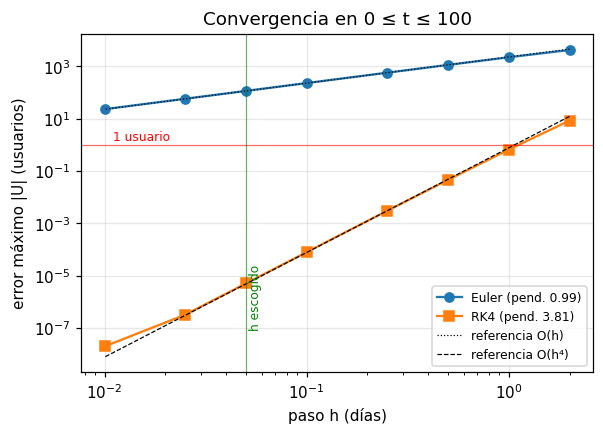

In [8]:
hs = np.array([2, 1, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01])
err = {'euler': [], 'rk4': []}
for h in hs:
    for m in err:
        t_, U_ = integrar(h, m)
        err[m].append(np.abs(U_ - ref.sol(t_)[0]).max())
err = {m: np.array(v) for m, v in err.items()}

# orden = pendiente en log-log (Euler: todos los h; RK4: zona asintótica h ≤ 0.5, antes del piso de redondeo)
ord_e = np.polyfit(np.log(hs), np.log(err['euler']), 1)[0]
sel = (hs <= 0.5) & (err['rk4'] > 1e-9)
ord_r = np.polyfit(np.log(hs[sel]), np.log(err['rk4'][sel]), 1)[0]
t22 = pd.DataFrame({'h (días)': hs, 'error máx Euler': err['euler'], 'error máx RK4': err['rk4'],
                    'pend. local Euler': np.r_[np.nan, np.diff(np.log(err['euler']))/np.diff(np.log(hs))],
                    'pend. local RK4': np.r_[np.nan, np.diff(np.log(err['rk4']))/np.diff(np.log(hs))]}).set_index('h (días)')
display(t22.style.format('{:.3e}', subset=['error máx Euler','error máx RK4']).format('{:.2f}', subset=['pend. local Euler','pend. local RK4']))
print(f"Orden estimado: Euler ≈ {ord_e:.2f}   RK4 ≈ {ord_r:.2f}")

plt.figure(figsize=(6, 4))
plt.loglog(hs, err['euler'], 'o-', label=f'Euler (pend. {ord_e:.2f})')
plt.loglog(hs, err['rk4'], 's-', label=f'RK4 (pend. {ord_r:.2f})')
plt.loglog(hs, err['euler'][3]*(hs/hs[3]), 'k:', lw=.8, label='referencia O(h)')
plt.loglog(hs, err['rk4'][3]*(hs/hs[3])**4, 'k--', lw=.8, label='referencia O(h⁴)')
plt.axhline(1, color='r', lw=.8, alpha=.6); plt.text(0.011, 1.4, '1 usuario', color='r', fontsize=8)
plt.axvline(P['h'], color='g', lw=.8, alpha=.6); plt.text(0.052, 1e-7, 'h escogido', color='g', fontsize=8, rotation=90)
plt.xlabel('paso h (días)'); plt.ylabel('error máximo |U| (usuarios)'); plt.title('Convergencia en 0 ≤ t ≤ 100')
plt.legend(fontsize=8); plt.show()

**Resultado 2.2b.**
- **Euler:** pendiente 0.99, orden 1; el error máximo es $\approx 2.3\times10^3\,h$ usuarios.
- **RK4:** pendiente 3.81 en el ajuste global, porque el punto $h=0.01$ ya toca el piso de la referencia. Las pendientes locales entre $h=1$ y $h=0.025$ están entre 3.85 y 3.98, así que el orden es 4.
- **Paso escogido: RK4 con $h=0.05$ días.**
  1. El error máximo es de $5\times10^{-6}$ usuarios, muchos órdenes por debajo de 1 usuario y del ruido del DES (±3 % en $W$).
  2. Divide exactamente a $H\in\{0.25, 1, 7\}$ y a $\Delta t\in\{0.25,1\}$, así que los pasos caen sobre los intercambios y las llegadas de servidores. Entre intercambios la $W$ es constante a trozos, y RK4 conserva su orden en cada trozo.
  3. Cuesta 2,000 pasos en 100 días, una cantidad despreciable frente al DES.
- **Euler queda descartado:** para un error menor a 1 usuario necesitaría $h<4\times10^{-4}$, unos 230,000 pasos.

---
# Task 2.3 — Autoescalado como evento de estado
## 2.3a  Implementación
- **Evento de estado:** $g(t)=\rho_{pred}(t)-\theta=aU/(c\mu)-\theta$ con dirección $\uparrow$. Solo está activo si no hay pedido pendiente.
  - **RK4 + bisección:** si en el paso $[t,t+h]$ ocurre $g<0\to g\ge 0$, se biseca sobre la longitud del sub-paso RK4 desde $t$ (tolerancia $10^{-10}$ días). El paso se corta ahí, se emite el pedido y se programa la llegada en $t^*+D$.
  - **`solve_ivp`:** el mismo $g$ como evento terminal con `direction=+1`.
- **Evento de tiempo (llegada):** el integrador detiene el paso exactamente en $t^*+D$ y suma 2 servidores.
- **Reorden inmediato:** al llegar los servidores, si $\rho_{pred}>\theta$ con el nuevo $c$, se emite otro pedido en ese mismo instante.
- **Intercambios SD↔DES:** el paso también se corta en cada múltiplo de $H$, porque ahí cambian $W$ y $r$.

Contraste de las dos implementaciones localizadas (modo `teoria`, sin ruido, y modo `des`, semilla 0):

In [9]:
for modo in ['teoria', 'des']:
    a1 = hibrido_eventos(modo=modo); a2 = hibrido_eventos_ivp(modo=modo)
    print(f"[{modo:6}] pedidos bisección = {np.round(a1['pedidos'], 6)}   solve_ivp = {np.round(a2['pedidos'], 6)}")
    print(f"         llegadas bisección = {np.round(a1['llegadas'], 6)}   solve_ivp = {np.round(a2['llegadas'], 6)}")
    print(f"         U(100): {a1['U100']:.4f} vs {a2['U100']:.4f}")
# comprobación analítica del primer cruce: con W<Wok antes del cruce, U(t) es el SD con δ0
U_cr = P['theta']*P['c0']*P['mu']/P['a']
t_cr = solve_ivp(fSD, (0, 100), [P['U0']], method='DOP853', rtol=1e-13, atol=1e-9,
                 events=lambda t, y: y[0] - U_cr).t_events[0][0]
print(f"Cruce teórico ρ_pred = θ  (U = {U_cr:.0f}):  t* = {t_cr:.6f} días")

[teoria] pedidos bisección = [15.737706 24.426106]   solve_ivp = [15.737706 24.426106]
         llegadas bisección = [20.737706 29.426106]   solve_ivp = [20.737706 29.426106]
         U(100): 19801.3377 vs 19801.3377
[des   ] pedidos bisección = [15.737706 24.641166]   solve_ivp = [15.737706 24.641166]
         llegadas bisección = [20.737706 29.641166]   solve_ivp = [20.737706 29.641166]
         U(100): 19801.3377 vs 19801.3377
Cruce teórico ρ_pred = θ  (U = 11200):  t* = 15.737706 días


**Resultado 2.3a.**
- Bisección y `solve_ivp` dan los mismos instantes (pedidos y llegadas) con 6 decimales en ambos modos.
- El primer cruce, $t^*=15.737706$, coincide con el cálculo independiente: antes del cruce $W<W_{ok}$, así que $U$ sigue el SD con $\delta_0$ hasta $U=\theta c\mu/a=11{,}200$.
- El segundo pedido (24.43 en teoría, 24.64 con DES) es un nuevo cruce con $c=6$ y $U=16{,}800$. Cambia con la semilla porque el abandono previo depende del ruido del DES.

## 2.3b  Tres versiones: localizada, ingenua con $\Delta t=1$ y con $\Delta t=0.25$
- **Columnas de la tabla:**
  - $W_{max}$ (DES) es la latencia máxima devuelta por el DES en los intercambios. Es la que "ve" el modelo.
  - $W_{max}$ real es el máximo de la latencia M/M/$c$/$K$ instantánea a lo largo de la trayectoria.
  - Exceso es $\int\max(0,W-W_{ok})\,dt$, en s·día.
- **Réplicas:** semilla 0, más la media de 20 réplicas con números aleatorios comunes.

In [10]:
versiones = {'Localizada (bisección)': lambda **k: hibrido_eventos(**k),
             'Ingenua Δt = 1':         lambda **k: hibrido_ingenuo(dt=1.0, **k),
             'Ingenua Δt = 0.25':      lambda **k: hibrido_ingenuo(dt=0.25, **k)}
def resumen(R):
    L = latencia_real(R, 0.02)
    return dict(primer_pedido=R['pedidos'][0], llegada_1=R['llegadas'][0],
                pedidos=len(R['pedidos']), c_final=R['c'], Wmax_DES=R['Wmax'], rmax_DES=R['rmax'],
                Wmax_real=L['Wmax'], rho_max=L['rho_max'], exceso_s_dia=L['exceso'], U100=R['U100'])
res0 = {v: resumen(f(seed=0)) for v, f in versiones.items()}
t23 = pd.DataFrame(res0).T; print('Semilla 0'); display(t23)

NREP = 20
reps = {v: [resumen(f(seed=s)) for s in range(NREP)] for v, f in versiones.items()}
filas = []
for v, lst in reps.items():
    d = {'versión': v}
    for k in ['primer_pedido', 'llegada_1', 'Wmax_DES', 'Wmax_real', 'exceso_s_dia', 'U100']:
        m, h = ic95([x[k] for x in lst]); d[k] = f'{m:.3f} ± {h:.3f}'
    filas.append(d)
print(f'Media ± IC 95 % sobre {NREP} réplicas (números aleatorios comunes)')
pd.DataFrame(filas).set_index('versión')

Semilla 0


,primer_pedido,llegada_1,pedidos,c_final,Wmax_DES,rmax_DES,Wmax_real,rho_max,exceso_s_dia,U100
Localizada (bisección),15.7377,20.7377,2.0000,8.0000,1.0322,0.0000,1.1046,0.8555,0.4526,"19,801.3377"
Ingenua Δt = 1,16.0000,21.0000,2.0000,8.0000,1.0322,0.0000,1.1046,0.8555,0.4900,"19,801.3377"
Ingenua Δt = 0.25,15.7500,20.7500,2.0000,8.0000,1.0322,0.0000,1.1046,0.8555,0.4548,"19,801.3377"


Media ± IC 95 % sobre 20 réplicas (números aleatorios comunes)


,primer_pedido,llegada_1,Wmax_DES,Wmax_real,exceso_s_dia,U100
versión,,,,,,
Localizada (bisección),15.738 ± 0.000,20.738 ± 0.000,1.069 ± 0.083,1.033 ± 0.050,0.450 ± 0.064,19801.338 ± 0.000
Ingenua Δt = 1,16.000 ± 0.000,21.000 ± 0.000,1.069 ± 0.083,1.043 ± 0.052,0.487 ± 0.067,19801.338 ± 0.000
Ingenua Δt = 0.25,15.750 ± 0.000,20.750 ± 0.000,1.069 ± 0.083,1.033 ± 0.051,0.452 ± 0.064,19801.338 ± 0.000


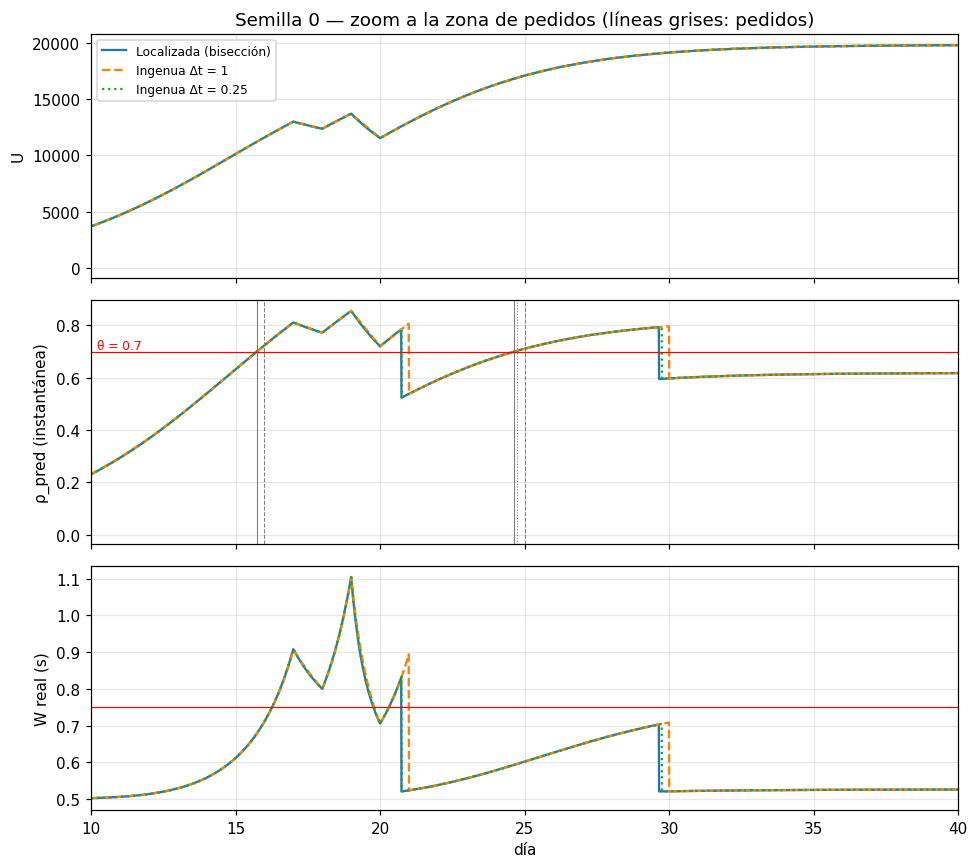

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for (v, f), st in zip(versiones.items(), ['-', '--', ':']):
    R = f(seed=0); L = latencia_real(R, 0.01)
    ax[0].plot(R['t'], R['U'], st, label=v)
    ax[1].plot(L['t'], L['rho'], st)
    ax[2].plot(L['t'], L['W'], st)
    for tp in R['pedidos']: ax[1].axvline(tp, ls=st, lw=.7, color='gray')
ax[1].axhline(P['theta'], color='r', lw=.8); ax[1].text(10.2, .71, 'θ = 0.7', color='r', fontsize=8)
ax[2].axhline(P['Wok'], color='r', lw=.8)
ax[0].set_ylabel('U'); ax[1].set_ylabel('ρ_pred (instantánea)'); ax[2].set_ylabel('W real (s)')
ax[2].set_xlabel('día'); ax[0].legend(fontsize=8); ax[0].set_xlim(10, 40)
ax[0].set_title('Semilla 0 — zoom a la zona de pedidos (líneas grises: pedidos)')
plt.tight_layout(); plt.show()

## 2.3c  ¿Cuándo hace más daño la detección tardía?
- **Barrido:** crecimiento $q$ × retraso $D$, en modo `teoria` (sin ruido, aísla el efecto de la detección).
- **Comparación:** versión localizada contra ingenua con $\Delta t=1$, con lazo cerrado y en cascada.
- **Experimento aparte:** se repite el grupo 3 con ventana $H=0.25$ para mostrar el enmascaramiento por la ventana de intercambio.

t_cruce  Wmax_loc  Wmax_ing  exceso_loc  exceso_ing  \
lazo    q      D                                                        
cerrado 0.3000 3  15.7377    0.9082    0.9281      0.2190      0.2603   
               5  15.7377    0.9314    0.9564      0.4165      0.4644   
               8  15.7377    0.9862    0.9862      0.7320      0.7441   
        0.4500 3  10.9388    1.1389    1.1799      0.3551      0.3802   
               5  10.9388    1.1960    1.1960      0.4841      0.5069   
               8  10.9388    1.1960    1.1960      0.9651      1.0032   
        0.6000 3   8.4037    1.0950    1.5524      0.4262      0.6790   
               5   8.4037    1.5942    1.5942      0.7809      0.8132   
               8   8.4037    1.5942    1.5942      1.0384      1.1939   
cascada 0.3000 3  15.7377    2.1527    2.5812      1.1150      1.5175   
               5  15.7377    5.5781    5.8102      7.6254      8.8426   
               8  15.7377    6.7021    6.7296     24.4043     25.8683   
        0.4500 3  10.9388    4.9994    5.1240      3.6210      3.7908   
               5  10.9388    6.6531    6.6652     14.4127     14.6363   
               8  10.9388    6.9205    6.9222     32.7844     33.0156   
        0.6000 3   8.4037    6.2988    6.6091      6.6064      9.7594   
               5   8.4037    6.8665    6.9060     18.5428     21.9345   
               8   8.4037    6.9699    6.9751     37.2696     40.6979   

                  daño_extra_pct  dias_rho1_loc  dias_rho1_ing  
lazo    q      D                                                
cerrado 0.3000 3         18.8604         0.0000         0.0000  
               5         11.4963         0.0000         0.0000  
               8          1.6565         0.0000         0.0000  
        0.4500 3          7.0733         0.0000         0.0000  
               5          4.7169         0.0000         0.0000  
               8          3.9554         0.0000         0.0000  
        0.6000 3         59.3058         0.0000         0.0000  
               5          4.1406         0.0000         0.0000  
               8         14.9770         0.0000         0.0000  
cascada 0.3000 3         36.1043         0.0000         0.0000  
               5         15.9619         1.0800         1.3200  
               8          5.9988         4.0800         4.3200  
        0.4500 3          4.6879         0.4000         0.4400  
               5          1.5515         2.4000         2.4400  
               8          0.7051         5.4000         5.4400  
        0.6000 3         47.7276         1.0800         1.6200  
               5         18.2915         3.0800         3.6200  
               8          9.1988         6.0800         6.6200

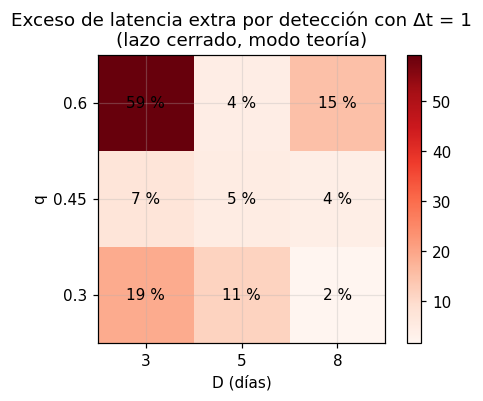

Enmascaramiento por la ventana de intercambio (grupo 3, modo teoría):
  H =  1.0:  Wmax_DES localizada = 0.931 s   ingenua Δt=1 = 0.931 s
  H = 0.25:  Wmax_DES localizada = 0.857 s   ingenua Δt=1 = 0.931 s


In [12]:
filas = []
for fb in [True, False]:
    for q in [0.30, 0.45, 0.60]:
        for D in [3, 5, 8]:
            Q = dict(P, modo='teoria', q=q, D=D)
            Le = latencia_real(hibrido_eventos(Q, feedback=fb), 0.02)
            Ri = hibrido_ingenuo(Q, dt=1.0, feedback=fb); Li = latencia_real(Ri, 0.02)
            filas.append(dict(lazo='cerrado' if fb else 'cascada', q=q, D=D,
                              t_cruce=hibrido_eventos(Q, feedback=fb)['pedidos'][0],
                              Wmax_loc=Le['Wmax'], Wmax_ing=Li['Wmax'],
                              exceso_loc=Le['exceso'], exceso_ing=Li['exceso'],
                              daño_extra_pct=100*(Li['exceso']-Le['exceso'])/Le['exceso'],
                              dias_rho1_loc=Le['dias_sat'], dias_rho1_ing=Li['dias_sat']))
t23c = pd.DataFrame(filas).set_index(['lazo', 'q', 'D']); display(t23c)

piv = t23c.loc['cerrado']['daño_extra_pct'].unstack()
plt.figure(figsize=(5, 3.4)); plt.imshow(piv.values, cmap='Reds', origin='lower')
for i in range(3):
    for j in range(3): plt.text(j, i, f'{piv.values[i, j]:.0f} %', ha='center', va='center')
plt.xticks(range(3), piv.columns); plt.yticks(range(3), piv.index)
plt.xlabel('D (días)'); plt.ylabel('q'); plt.title('Exceso de latencia extra por detección con Δt = 1\n(lazo cerrado, modo teoría)')
plt.colorbar(); plt.show()

print('Enmascaramiento por la ventana de intercambio (grupo 3, modo teoría):')
for H in [1.0, 0.25]:
    Q = dict(P, modo='teoria', H=H)
    print(f"  H = {H:4}:  Wmax_DES localizada = {hibrido_eventos(Q)['Wmax']:.3f} s   ingenua Δt=1 = {hibrido_ingenuo(Q, dt=1)['Wmax']:.3f} s")

**Diferencia entre las tres versiones (2.3b, grupo 3, $H=1$).**

| | Localizada | Ingenua $\Delta t=1$ | Ingenua $\Delta t=0.25$ |
|---|---|---|---|
| 1.er pedido (día) | 15.738 | 16.000 (+0.262) | 15.750 (+0.012) |
| Llegada (día) | 20.738 | 21.000 | 20.750 |
| $W_{max}$ que ve el modelo (DES) | 1.069 s | 1.069 s | 1.069 s |
| $W_{max}$ real | 1.033 s | 1.043 s | 1.033 s |
| Exceso $\int (W-W_{ok})^+dt$ | 0.450 | 0.487 (+8 %) | 0.452 |
| $U(100)$ | 19,801.3 | 19,801.3 | 19,801.3 |

- **Retraso de detección:** la versión ingenua emite el pedido con un retraso igual a $\lceil t^*/\Delta t\rceil\Delta t - t^*$, uniforme en $[0,\Delta t)$, que se arrastra a la llegada y a los reórdenes.
- **Con $H=1$ el modelo no ve el error.** Las tres llegadas caen en $(20,21]$, y la versión ingenua procesa la llegada en $t=21$ antes del intercambio. Por eso, en todos los intercambios el DES recibe el mismo $c$, devuelve la misma $W$ y $U(t)$ queda idéntica. La ventana de intercambio **enmascara** la detección tardía.
- **El daño existe aunque el modelo no lo vea:** la latencia real que vive el usuario entre 20.74 y 21 es más alta (+8 % de exceso). Con $H=0.25$ el modelo sí lo ve: $W_{max}$ es 0.857 s en la localizada contra 0.931 s en la ingenua.

**Cuándo hace más daño la detección tardía (barrido 2.3c).**
- **Peor caso: crecimiento rápido con $D$ corto.** Con $q=0.6$ y $D=3$, $W_{max}$ real sube de 1.10 a 1.55 s (+59 % de exceso con lazo y +48 % en cascada).
  - El tiempo para pasar de $\rho=0.7$ a $\rho=1$ es $\approx \dfrac{0.3\,c\mu/a}{dU/dt}$, unos 1.6 días con $q=0.6$.
  - Cuando $D$ es comparable a ese tiempo, la política llega "justo a tiempo", y un retraso extra de hasta $\Delta t$ basta para entrar en saturación.
- **Con $D$ largo** ($D=8$) el clúster se satura de todos modos. El retraso añade poco en términos relativos (2–15 %), aunque en cascada suma 0.04–0.54 días adicionales con $\rho\ge1$.
- **El daño no es monótono en $q$.** Depende de dónde cae el cruce dentro del paso: el retraso es 0.26 d con $q=0.3$, 0.06 d con $q=0.45$ y 0.60 d con $q=0.6$. Por eso $q=0.45$ sale menos dañado que $q=0.3$.
- **Condiciones de máximo daño:**
  - $dU/dt$ alto en el cruce;
  - $D$ del mismo orden que el tiempo entre $\theta$ y la saturación;
  - $\Delta t$ grande y cruce al inicio del paso;
  - $H\le\Delta t$, para que el DES llegue a registrarlo;
  - lazo débil (cascada), porque no hay abandono que frene a $U$.

---
# Task 2.4 — Interfaz SD ↔ DES
## 2.4a  Llegadas en la parte medida: ¿conteo de Poisson?
- 30 ventanas con $\lambda=5$, $c=4$ y $K=60$.
- En la parte medida (600 s) se espera $N\sim\text{Poisson}(\lambda\cdot 600=3000)$, así que $\mathbb E[N]=\text{Var}[N]=3000$.

Conteos (primeros 10): [2931 2936 2997 3014 3090 3031 2982 3013 3048 2960]
Media   = 2983.7 ± 19.8  (esperado 3000)   z = -1.63, p = 0.102
Varianza muestral = 2802.1  (esperado 3000)   Var/Media = 0.939
Prueba de dispersión χ²(29) = 27.2,  p = 0.882
KS contra N(3000, 3000): p = 0.138


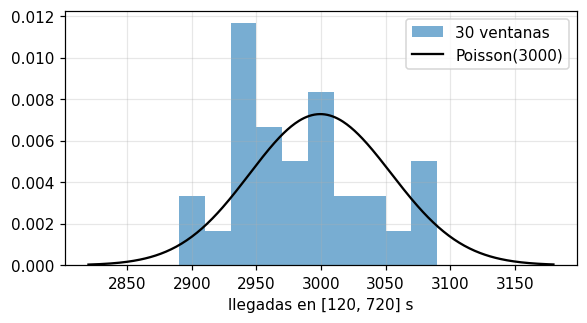

In [13]:
cnt = np.array([simular_des(5, 4, K=60, rng=np.random.default_rng([24, i]))['lleg_med'] for i in range(30)])
esp = 5*600
m, h = ic95(cnt); v = cnt.var(ddof=1)
D_ = (cnt - cnt.mean())**2
chi = D_.sum()/cnt.mean()                     # índice de dispersión: ~ χ²(n-1) si es Poisson
p_disp = 2*min(stats.chi2.cdf(chi, 29), stats.chi2.sf(chi, 29))
z = (cnt.mean() - esp)/np.sqrt(esp/30)
p_media = 2*stats.norm.sf(abs(z))
p_ks = stats.kstest((cnt - esp)/np.sqrt(esp), 'norm').pvalue   # Poisson(3000) ≈ N(3000, 3000)
print(f"Conteos (primeros 10): {cnt[:10]}")
print(f"Media   = {m:.1f} ± {h:.1f}  (esperado {esp})   z = {z:.2f}, p = {p_media:.3f}")
print(f"Varianza muestral = {v:.1f}  (esperado {esp})   Var/Media = {v/m:.3f}")
print(f"Prueba de dispersión χ²(29) = {chi:.1f},  p = {p_disp:.3f}")
print(f"KS contra N(3000, 3000): p = {p_ks:.3f}")
plt.figure(figsize=(6, 3)); plt.hist(cnt, bins=10, density=True, alpha=.6, label='30 ventanas')
x = np.arange(2820, 3181); plt.plot(x, stats.poisson.pmf(x, esp), 'k', label='Poisson(3000)')
plt.xlabel('llegadas en [120, 720] s'); plt.legend(); plt.show()

**Resultado 2.4a.**
- **Media:** 2,983.7 ± 19.8, que contiene a 3,000 ($z=-1.63$, $p=0.10$).
- **Dispersión:** Var/Media = 0.94, y la prueba de dispersión da $\chi^2_{29}=27.2$ con $p=0.88$.
- **Forma:** KS contra $N(3000,3000)$ da $p=0.14$.
- El conteo de la parte medida se comporta como Poisson($\lambda\cdot600$). La interfaz entrega la tasa correcta y no pierde ni duplica llegadas al cortar el calentamiento.

## 2.4b  Conservación de entidades
- **Ventana completa** (arranca vacía): llegaron = atendidas + rechazadas + dentro en $T$.
- **Parte medida:** dentro en 120 s + llegaron = atendidas + rechazadas + dentro en 720 s.
- Se revisan 12 ventanas con $c=4$, $K=60$ y $\lambda$ de 5 a 15 (sobrecarga desde $\lambda>8$).

In [14]:
filas = []
for lam in [5, 7, 9, 10, 12, 15]:
    for s in range(2):
        o = simular_des(lam, 4, K=60, rng=np.random.default_rng([25, int(lam*10), s]))
        bal_tot = o['lleg_tot'] - (o['atend_tot'] + o['rech_tot'] + o['N_T'])
        bal_med = o['N_warm'] + o['lleg_med'] - (o['atend_med'] + o['rech_med'] + o['N_T'])
        filas.append(dict(λ=lam, ρ=lam/8, réplica=s, llegaron=o['lleg_tot'], atendidas=o['atend_tot'],
                          rechazadas=o['rech_tot'], dentro_T=o['N_T'], balance_total=bal_tot,
                          dentro_120=o['N_warm'], lleg_med=o['lleg_med'], atend_med=o['atend_med'],
                          rech_med=o['rech_med'], balance_medido=bal_med))
t24b = pd.DataFrame(filas).set_index(['λ', 'réplica'])
display(t24b.style.format(precision=3, subset=['ρ']))
print('¿Todos los balances son 0?', (t24b[['balance_total', 'balance_medido']] == 0).all().all())

¿Todos los balances son 0? True


**Resultado 2.4b.**
- Las 12 ventanas, 8 de ellas sobrecargadas ($\lambda\ge9$), cierran con balance 0 tanto en la ventana completa como en la parte medida.
- No se pierden ni se duplican solicitudes, ni siquiera cuando hay rechazos masivos (≈47 % con $\lambda=15$).

## 2.4c  Regla de calentamiento
Evidencia: media de $N(t)$ sobre 100 réplicas que arrancan vacías, y sesgo de medir sin descartar nada.

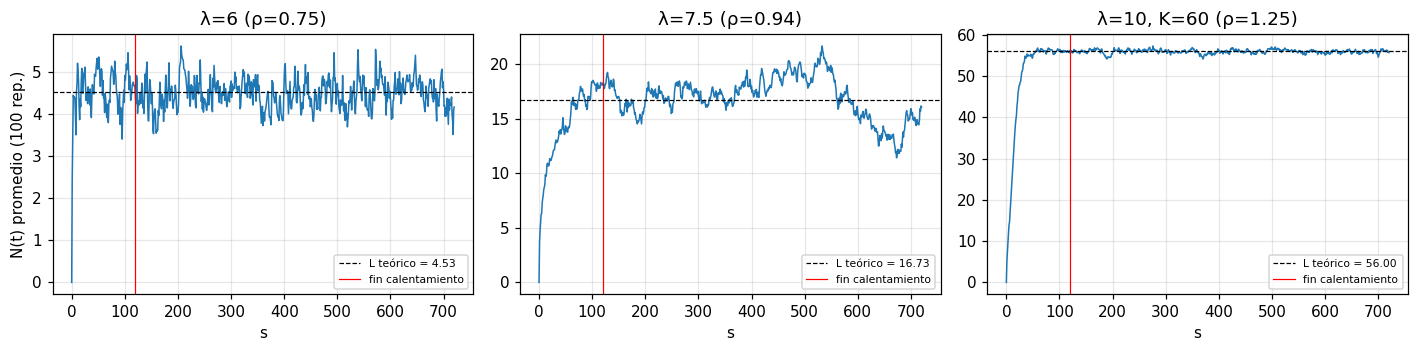

W_sim   IC95  W_teórico  sesgo_W_pct  \
caso                calentamiento_s                                         
λ=6 (ρ=0.75)        0.0000          0.7533 0.0101     0.7547      -0.1935   
                    120.0000        0.7574 0.0117     0.7547       0.3591   
λ=7.5 (ρ=0.94)      0.0000          2.2331 0.2137     2.2301       0.1352   
                    120.0000        2.3049 0.2480     2.2301       3.3565   
λ=10, K=60 (ρ=1.25) 0.0000          6.8527 0.0288     7.0000      -2.1047   
                    120.0000        6.9994 0.0293     7.0000      -0.0089   

                                     r_sim  r_teórico  
caso                calentamiento_s                    
λ=6 (ρ=0.75)        0.0000          0.0000     0.0000  
                    120.0000        0.0000     0.0000  
λ=7.5 (ρ=0.94)      0.0000          0.0000     0.0000  
                    120.0000        0.0000     0.0000  
λ=10, K=60 (ρ=1.25) 0.0000          0.1926     0.2000  
                    120.0000        0.1984     0.2000

In [15]:
grid = np.linspace(0, 720, 721)
def N_medio(lam, K, nrep=100):
    acc = np.zeros_like(grid)
    for i in range(nrep):
        tt, nn = simular_des(lam, 4, K=K, rng=np.random.default_rng([26, int(lam*10), i]), traza=True)['traza']
        acc += nn[np.searchsorted(tt, grid, side='right') - 1]
    return acc/nrep
casos = [(6, 10**9, 'λ=6 (ρ=0.75)'), (7.5, 10**9, 'λ=7.5 (ρ=0.94)'), (10, 60, 'λ=10, K=60 (ρ=1.25)')]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a_, (lam, K, nom) in zip(ax, casos):
    Nm = N_medio(lam, K)
    Lth = mmc(lam, 4)['L'] if K > 1e6 else mmck(lam, 4, K)['L']
    a_.plot(grid, Nm, lw=1); a_.axhline(Lth, color='k', ls='--', lw=.8, label=f'L teórico = {Lth:.2f}')
    a_.axvline(120, color='r', lw=.8, label='fin calentamiento'); a_.set_title(nom); a_.set_xlabel('s'); a_.legend(fontsize=7)
ax[0].set_ylabel('N(t) promedio (100 rep.)'); plt.tight_layout(); plt.show()

filas = []
for lam, K, nom in casos:
    th_ = mmc(lam, 4) if K > 1e6 else mmck(lam, 4, K)
    for warm in [0.0, 120.0]:
        rr = [simular_des(lam, 4, K=K, warm=warm, rng=np.random.default_rng([27, int(lam*10), i])) for i in range(100)]
        mW, hW = ic95([x['W'] for x in rr])
        filas.append(dict(caso=nom, calentamiento_s=warm, W_sim=mW, IC95=hW, W_teórico=th_['W'],
                          sesgo_W_pct=100*(mW - th_['W'])/th_['W'],
                          r_sim=np.mean([x['r'] for x in rr]), r_teórico=th_.get('PK', 0.0)))
t24c = pd.DataFrame(filas).set_index(['caso', 'calentamiento_s']); t24c

**Regla de calentamiento escogida.**
- **Cómo es cada ventana:** cada intercambio lanza una ventana DES **independiente** que arranca **vacía**, con la $\lambda=aU$ y el $c$ vigentes y una semilla propia $(\text{seed},k)$. Se simulan 720 s, se descartan los primeros 120 y se mide sobre 600 s.
- **Qué se mide:**
  - $r$ se cuenta sobre las llegadas posteriores a 120 s;
  - $W$ se promedia sobre las solicitudes aceptadas que llegan en $[120,720]$, siguiendo cada una hasta su salida (sin llegadas nuevas después de 720 s), para no truncar los tiempos más largos.
- **Por qué 120 s alcanzan:** las curvas de $N(t)$ muestran que el estado estacionario se alcanza en segundos con $\rho=0.75$ y en unos 30 s con sobrecarga, que es el tiempo de llenado $K/(\lambda-c\mu)$.
- **Límite cerca de $\rho\approx0.94$:** la relajación tarda unos 100 s, así que 120 s apenas alcanzan. El tiempo de relajación crece del orden de $(1-\sqrt\rho)^{-2}$, y para $\rho\to1$ habría que alargar el calentamiento o arrancar desde la distribución estacionaria.
- **Sesgo si la ventana arranca vacía y no se descarta nada:**
  - es **hacia abajo**, porque los primeros segundos no tienen cola ni rechazos;
  - con sobrecarga se mide $W=6.85$ s contra 7.00 s ($-2.1$ %, fuera del IC) y $r=0.193$ contra 0.200 ($-3.7$ %);
  - con $\rho=0.75$ es despreciable ($-0.2$ %).
- **Consecuencia para el híbrido:** el sesgo se concentra en los días de sobrecarga, justo los que alimentan el abandono. Subestimar $W$ y $r$ subestima $\delta$, sobrestima $U$ y hace que la política de autoescalado parezca mejor de lo que es.
- **Sesgo más grave en la línea base del Task 1.3:** solo cuenta las salidas dentro de la ventana, así que pierde precisamente las solicitudes que más esperan.

---
## Resumen del Task 2
1. **DES (2.1):** reproduce M/M/$c$ con la teoría dentro del IC 95 % y Little cierra con error menor a 0.05 %. $1-c\mu/\lambda$ es exacta solo en el límite de servidores siempre ocupados.
2. **SD (2.2):** RK4 propio de orden 4 frente a Euler de orden 1. Se usa RK4 con $h=0.05$ días, con error de $5\times10^{-6}$ usuarios y pasos alineados con los eventos.
3. **Evento de estado (2.3):** la bisección y `solve_ivp` coinciden ($t^*=15.7377$). Con $\Delta t=1$ el pedido se retrasa 0.26 días y la latencia real tiene 8 % más de exceso. Con $H=1$ el DES no lo ve, porque la ventana enmascara el error. El daño es mayor con crecimiento rápido y $D$ corto (hasta +59 %).
4. **Interfaz (2.4):** las llegadas son Poisson, las entidades se conservan en las 12 ventanas, y el calentamiento de 120 s elimina un sesgo de −2 a −4 % en sobrecarga.